# ML Analysis — K-Means on Nutrition

Data source: Open Food Facts (ODbL) — https://world.openfoodfacts.org/

In [1]:

import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)


Python executable: /home/nanma/lab-network/openfoodfacts-network-project/.venv/bin/python
Python version: 3.14.4 (main, Aug 20 2026, 10:41:58) [GCC 15.2.0]


## 1. Load ml_products.csv

In [2]:

import pandas as pd
from pathlib import Path

# Find the project folder
ROOT = Path.cwd().resolve()

if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent

# Location of our dataset
DATA_FILE = ROOT / "data" / "processed" / "ml_products.csv"

# Load the dataset
df = pd.read_csv(DATA_FILE, dtype={"barcode": str})

# Verify the dataset
print("Number of products:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

# Display first 5 products
display(df.head())


Number of products: 200
Number of columns: 11

Column names:
['barcode', 'product_name', 'brand', 'category', 'sugar_100g', 'fat_100g', 'protein_100g', 'salt_100g', 'calories_100g', 'calories_estimated', 'nutriscore']


,barcode,product_name,brand,category,sugar_100g,fat_100g,protein_100g,salt_100g,calories_100g,calories_estimated,nutriscore
0,3168930010265,cruesly mélange de noix,"Cruesli, Quaker",breakfast-cereals,12.0,19.0,8.5,0.00,462.0,False,B
1,3229820019307,Flocons d'avoine,Bjorg,breakfast-cereals,1.7,7.1,11.0,0.02,362.0,False,A
2,3229820129488,"muesli raisin,datte,figue",Bjorg,breakfast-cereals,14.0,5.8,11.0,0.03,352.0,False,A
3,5010477348678,Special Muesli 30% fruits & noix,The Jordans & Ryvita Company Limited - A Divis...,breakfast-cereals,17.0,7.2,10.0,0.03,360.0,False,A
4,3387390123210,Chocapic,"Nestlé, Chocapic",breakfast-cereals,19.9,4.4,8.5,0.20,384.0,False,B


## 2. Cleaning (duplicates, impossible values) and exclusion counts

In [3]:

# Nutritional columns to check
features = [
    "sugar_100g",
    "fat_100g",
    "protein_100g",
    "salt_100g",
    "calories_100g"
]

# Make a copy of our dataset
df_clean = df.copy()

# Convert nutritional values to numbers
for col in features:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

# 1. Check duplicate barcodes
duplicates = df_clean.duplicated(
    subset=["barcode"]
).sum()

# 2. Check missing nutritional values
missing = df_clean[features].isna().any(axis=1)

# 3. Check impossible nutritional values
nutrients = features[:-1]

invalid_nutrients = (
    (df_clean[nutrients] < 0) |
    (df_clean[nutrients] > 100)
).any(axis=1)

invalid_calories = (
    (df_clean["calories_100g"] < 0) |
    (df_clean["calories_100g"] > 900)
)

invalid = invalid_nutrients | invalid_calories

# 4. Remove invalid rows and duplicates
df_clean = df_clean.loc[
    ~(missing | invalid)
].drop_duplicates(subset=["barcode"]).reset_index(drop=True)

# 5. Display results
print("Original products:", len(df))
print("Duplicate barcodes:", duplicates)
print("Rows with missing nutrients:", missing.sum())
print("Rows with impossible values:", invalid.sum())
print("Final products:", len(df_clean))

print("\nProducts per category:")
print(df_clean["category"].value_counts())


Original products: 200
Duplicate barcodes: 0
Rows with missing nutrients: 0
Rows with impossible values: 0
Final products: 200

Products per category:
category
breakfast-cereals    50
biscuits             50
chocolates           50
yogurts              50
Name: count, dtype: int64


## 3. EDA: distributions, categories, correlations

Nutritional statistics:


,sugar_100g,fat_100g,protein_100g,salt_100g,calories_100g
count,200.00,200.00,200.00,200.00,200.00
mean,17.84,18.03,7.61,0.21,374.25
std,13.41,15.43,2.82,0.29,188.74
min,0.00,0.10,0.80,0.00,40.80
25%,7.45,5.48,5.68,0.03,144.50
50%,15.05,15.00,8.00,0.12,440.00
75%,25.00,26.50,9.40,0.22,505.75
max,55.00,59.00,21.00,1.40,655.00


NameError: name 'plt' is not defined

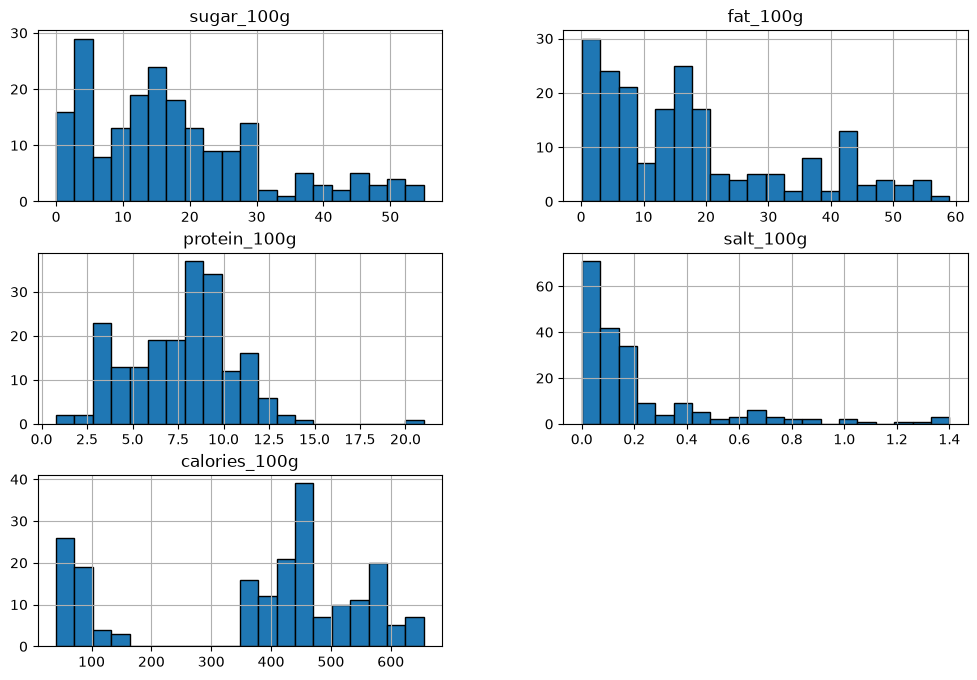

In [4]:

# Summary statistics for nutritional values
print("Nutritional statistics:")
display(df_clean[features].describe().round(2))

# Plot the distribution of each feature
df_clean[features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Nutritional Values", fontsize=16)
plt.tight_layout()
plt.show()


Average nutritional values by category:


,sugar_100g,fat_100g,protein_100g,salt_100g,calories_100g
category,,,,,
biscuits,19.38,16.46,7.59,0.48,436.55
breakfast-cereals,14.18,10.65,9.97,0.17,408.02
chocolates,30.83,41.43,8.07,0.06,573.40
yogurts,6.97,3.57,4.80,0.13,79.02


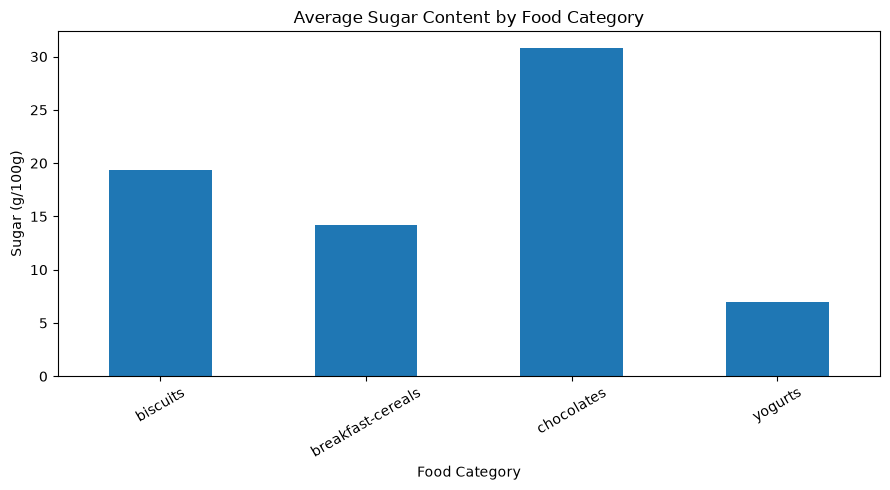

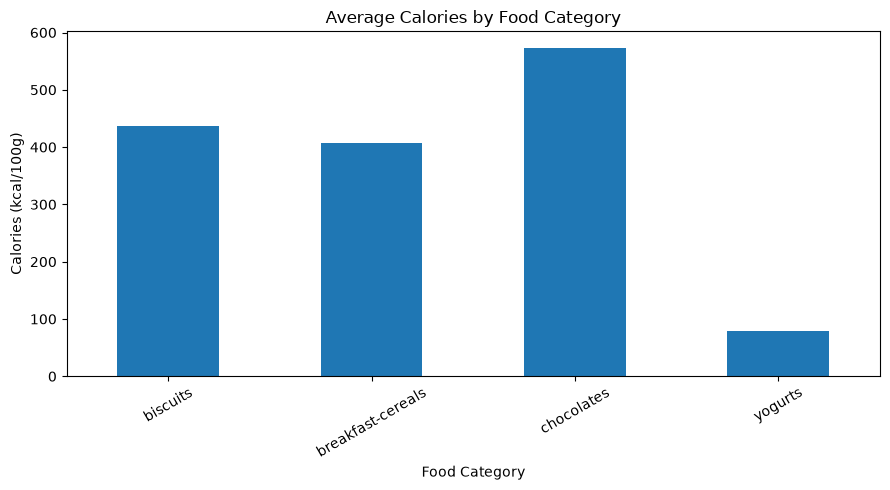

In [ ]:
import matplotlib.pyplot as plt


# Calculate average nutritional values per category
category_means = df_clean.groupby("category")[features].mean()

print("Average nutritional values by category:")
display(category_means.round(2))

# Compare average sugar content
category_means["sugar_100g"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Sugar Content by Food Category"
)

plt.ylabel("Sugar (g/100g)")
plt.xlabel("Food Category")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Compare average calorie content
category_means["calories_100g"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Calories by Food Category"
)

plt.ylabel("Calories (kcal/100g)")
plt.xlabel("Food Category")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



Correlation matrix:


,sugar_100g,fat_100g,protein_100g,salt_100g,calories_100g
sugar_100g,1.00,0.47,-0.04,0.18,0.58
fat_100g,0.47,1.00,0.24,-0.15,0.81
protein_100g,-0.04,0.24,1.00,-0.12,0.51
salt_100g,0.18,-0.15,-0.12,1.00,0.09
calories_100g,0.58,0.81,0.51,0.09,1.00


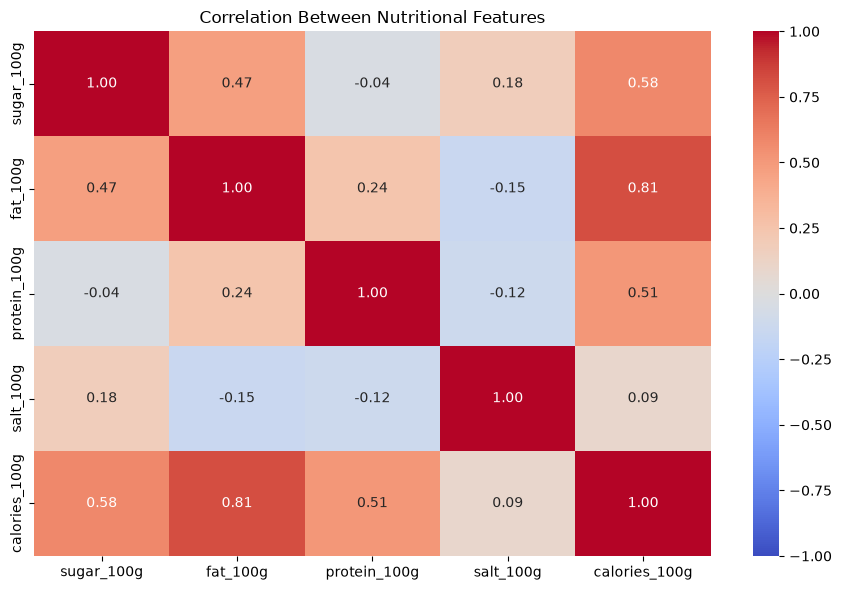

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlations between nutritional features
correlation_matrix = df_clean[features].corr()

print("Correlation matrix:")
display(correlation_matrix.round(2))

# Create correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Nutritional Features")
plt.tight_layout()
plt.show()


## 4. Features + StandardScaler

In [ ]:

from sklearn.preprocessing import StandardScaler

# Select the five nutritional features
X = df_clean[features].copy()

# Create the scaler
scaler = StandardScaler()

# Standardize the data
X_scaled = scaler.fit_transform(X)

# Convert standardized values to a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

print("Original nutritional values:")
display(X.head())

print("\nStandardized nutritional values:")
display(X_scaled_df.head().round(2))

print("\nMean after standardization:")
print(X_scaled_df.mean().round(2))

print("\nStandard deviation after standardization:")
print(X_scaled_df.std(ddof=0).round(2))

print("\nShape:", X_scaled.shape)


Original nutritional values:


,sugar_100g,fat_100g,protein_100g,salt_100g,calories_100g
0,12.0,19.0,8.5,0.00,462.0
1,1.7,7.1,11.0,0.02,362.0
2,14.0,5.8,11.0,0.03,352.0
3,17.0,7.2,10.0,0.03,360.0
4,19.9,4.4,8.5,0.20,384.0



Standardized nutritional values:


,sugar_100g,fat_100g,protein_100g,salt_100g,calories_100g
0,-0.44,0.06,0.32,-0.75,0.47
1,-1.21,-0.71,1.20,-0.68,-0.07
2,-0.29,-0.79,1.20,-0.64,-0.12
3,-0.06,-0.70,0.85,-0.64,-0.08
4,0.15,-0.89,0.32,-0.04,0.05



Mean after standardization:
sugar_100g      -0.0
fat_100g         0.0
protein_100g     0.0
salt_100g        0.0
calories_100g   -0.0
dtype: float64

Standard deviation after standardization:
sugar_100g       1.0
fat_100g         1.0
protein_100g     1.0
salt_100g        1.0
calories_100g    1.0
dtype: float64

Shape: (200, 5)


## 5. Choose K (2–6): elbow + silhouette

K=2 | Inertia=633.05 | Silhouette=0.392
K=3 | Inertia=438.84 | Silhouette=0.423
K=4 | Inertia=286.93 | Silhouette=0.476
K=5 | Inertia=222.30 | Silhouette=0.488
K=6 | Inertia=193.83 | Silhouette=0.438


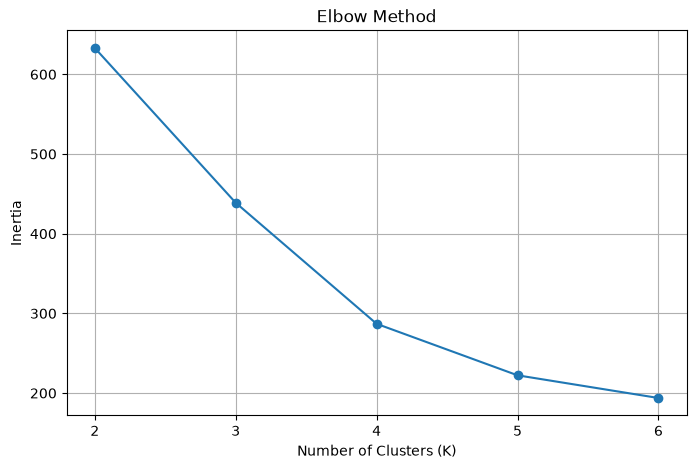

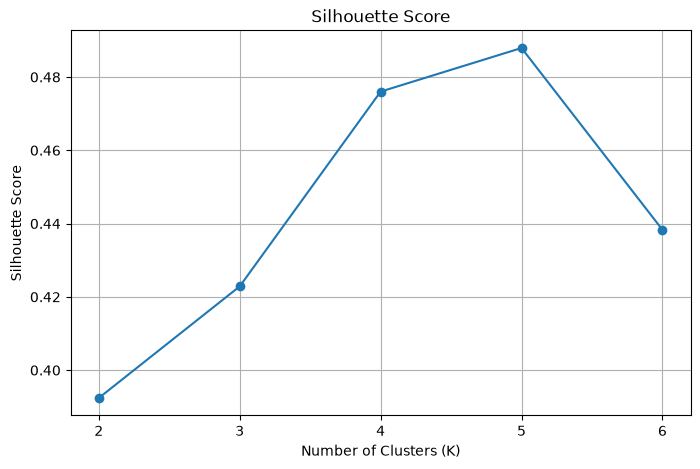

In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_values = range(2, 7)

inertias = []
silhouette_scores = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(
        f"K={k} | Inertia={model.inertia_:.2f} "
        f"| Silhouette={score:.3f}"
    )

# Elbow method graph
plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    inertias,
    marker="o"
)
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Silhouette score graph
plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)
plt.title("Silhouette Score")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


## 6. Fit KMeans(random_state=42, n_init=10) + PCA plot

K-Means clustering completed!

Products per cluster:
kmeans_cluster
0    68
1    30
2    51
3    30
4    21
Name: count, dtype: int64


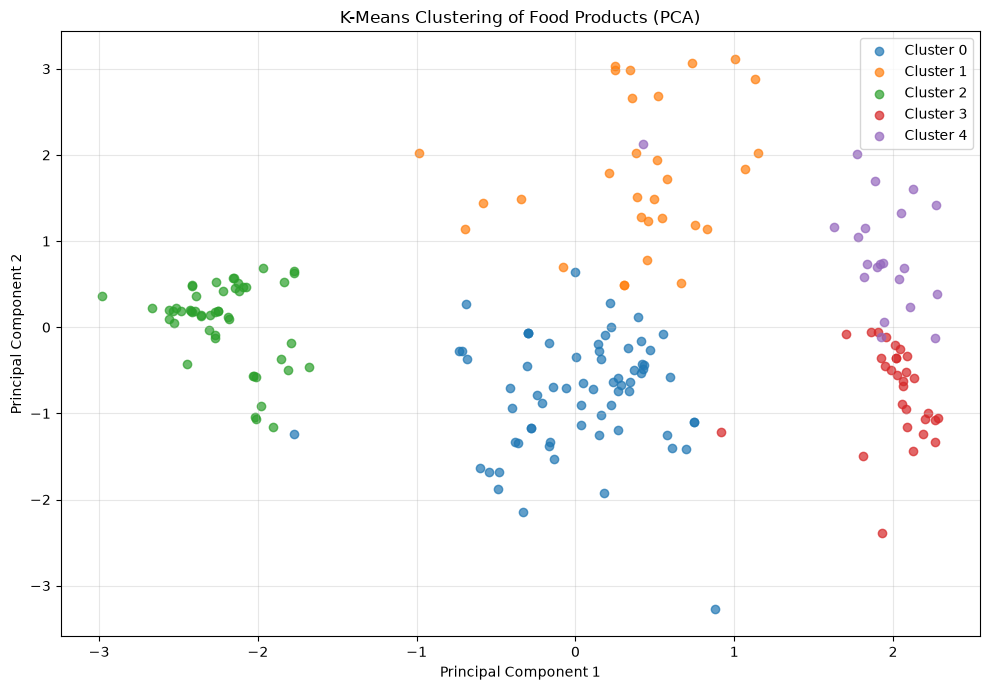


Explained variance by PCA:
[0.4805476  0.24541178]
Total: 0.7259593791208865


In [ ]:

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 1. Train the final K-Means model
best_k = 5

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

# 2. Assign each product to a cluster
df_clean["kmeans_cluster"] = kmeans_model.fit_predict(X_scaled)

print("K-Means clustering completed!")
print("\nProducts per cluster:")
print(df_clean["kmeans_cluster"].value_counts().sort_index())

# 3. Reduce the five nutritional features to two dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 4. Visualize the clusters
plt.figure(figsize=(10, 7))

for cluster in sorted(df_clean["kmeans_cluster"].unique()):
    mask = df_clean["kmeans_cluster"].to_numpy() == cluster

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.title("K-Means Clustering of Food Products (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nExplained variance by PCA:")
print(pca.explained_variance_ratio_)
print("Total:", pca.explained_variance_ratio_.sum())



6.1 Agglomerative Hierarchical Clustering

K=2 | Silhouette=0.392
K=3 | Silhouette=0.422
K=4 | Silhouette=0.470
K=5 | Silhouette=0.483
K=6 | Silhouette=0.465


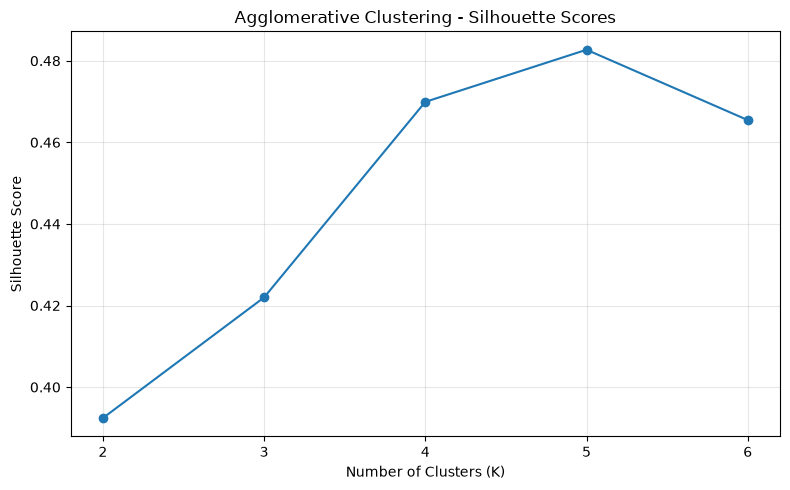


Agglomerative clustering completed!

Products per cluster:
hierarchical_cluster
0    52
1    35
2    32
3    65
4    16
Name: count, dtype: int64


In [ ]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Test different numbers of clusters
hierarchical_scores = []

for k in range(2, 7):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    hierarchical_scores.append(score)

    print(f"K={k} | Silhouette={score:.3f}")


# Visualize silhouette scores
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 7),
    hierarchical_scores,
    marker="o"
)

plt.title("Agglomerative Clustering - Silhouette Scores")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 7))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Fit the final model with K=5
hierarchical_model = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

df_clean["hierarchical_cluster"] = (
    hierarchical_model.fit_predict(X_scaled)
)

print("\nAgglomerative clustering completed!")

print("\nProducts per cluster:")
print(
    df_clean["hierarchical_cluster"]
    .value_counts()
    .sort_index()
)


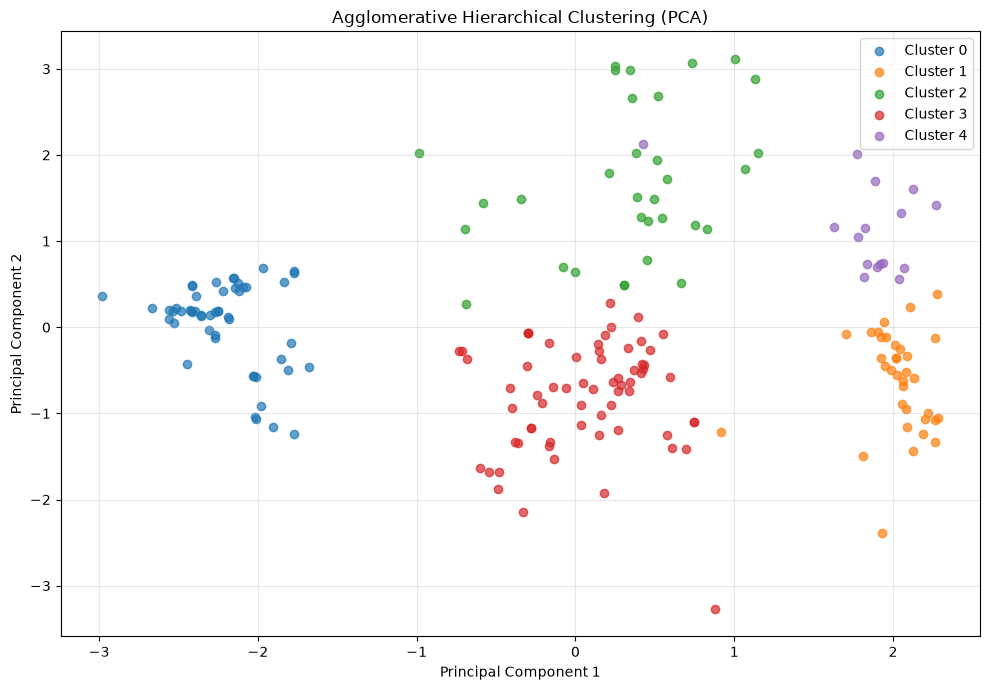

In [ ]:

plt.figure(figsize=(10, 7))

for cluster in sorted(df_clean["hierarchical_cluster"].unique()):

    mask = (
        df_clean["hierarchical_cluster"].to_numpy() == cluster
    )

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.title("Agglomerative Hierarchical Clustering (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

nutritional_cols = [
    'sugar_100g',
    'fat_100g',
    'protein_100g',
    'salt_100g',
    'calories_100g'
]

# K-Means nutritional profiles
print("K-MEANS: Average nutritional values per cluster")

display(
    df_clean.groupby('kmeans_cluster')[nutritional_cols]
    .mean()
    .round(2)
)

# Agglomerative nutritional profiles
print("AGGLOMERATIVE: Average nutritional values per cluster")

display(
    df_clean.groupby('hierarchical_cluster')[nutritional_cols]
    .mean()
    .round(2)
)


K-MEANS: Average nutritional values per cluster


,sugar_100g,fat_100g,protein_100g,salt_100g,calories_100g
kmeans_cluster,,,,,
0,12.97,12.66,9.85,0.13,414.31
1,24.85,16.07,7.07,0.79,452.98
2,6.86,3.58,4.54,0.13,78.78
3,20.38,46.81,8.97,0.03,592.93
4,46.62,32.15,6.63,0.12,537.19


AGGLOMERATIVE: Average nutritional values per cluster


,sugar_100g,fat_100g,protein_100g,salt_100g,calories_100g
hierarchical_cluster,,,,,
0,6.80,3.51,4.66,0.13,78.46
1,23.05,45.45,8.89,0.04,588.17
2,24.34,15.37,7.18,0.77,448.85
3,12.99,13.10,9.86,0.12,420.57
4,48.98,30.56,6.07,0.14,530.18


In [ ]:

for algorithm, cluster_col in [
    ("K-Means", "kmeans_cluster"),
    ("Agglomerative", "hierarchical_cluster")
]:

    print("\n" + "=" * 50)
    print(algorithm)
    print("=" * 50)

    print("\nFood category distribution (%)")

    display(
        pd.crosstab(
            df_clean[cluster_col],
            df_clean['category'],
            normalize='index'
        ).mul(100).round(1)
    )

    print("\nNutri-Score distribution (%)")

    display(
        pd.crosstab(
            df_clean[cluster_col],
            df_clean['nutriscore'],
            normalize='index'
        ).mul(100).round(1)
    )



K-Means

Food category distribution (%)


category,biscuits,breakfast-cereals,chocolates,yogurts
kmeans_cluster,,,,
0,36.8,61.8,0.0,1.5
1,73.3,26.7,0.0,0.0
2,3.9,0.0,0.0,96.1
3,0.0,0.0,100.0,0.0
4,4.8,0.0,95.2,0.0



Nutri-Score distribution (%)


nutriscore,A,B,C,D,E
kmeans_cluster,,,,,
0,26.5,32.4,38.2,2.9,0.0
1,0.0,0.0,20.0,26.7,53.3
2,24.5,20.4,49.0,6.1,0.0
3,0.0,0.0,0.0,53.3,46.7
4,0.0,0.0,0.0,0.0,100.0



Agglomerative

Food category distribution (%)


category,biscuits,breakfast-cereals,chocolates,yogurts
hierarchical_cluster,,,,
0,3.8,0.0,0.0,96.2
1,0.0,0.0,100.0,0.0
2,68.8,31.2,0.0,0.0
3,38.5,61.5,0.0,0.0
4,6.2,0.0,93.8,0.0



Nutri-Score distribution (%)


nutriscore,A,B,C,D,E
hierarchical_cluster,,,,,
0,26.0,20.0,48.0,6.0,0.0
1,0.0,0.0,0.0,45.7,54.3
2,3.1,0.0,21.9,25.0,50.0
3,24.6,33.8,38.5,3.1,0.0
4,0.0,0.0,0.0,0.0,100.0


In [ ]:

from sklearn.metrics import adjusted_rand_score

# Compare the two clustering algorithms
ari = adjusted_rand_score(
    df_clean['kmeans_cluster'],
    df_clean['hierarchical_cluster']
)

print("Clustering Agreement")
print("--------------------")
print(f"Adjusted Rand Index: {ari:.4f}")

# Compare cluster assignments
print("\nCluster correspondence:")
display(
    pd.crosstab(
        df_clean['kmeans_cluster'],
        df_clean['hierarchical_cluster']
    )
)


Clustering Agreement
--------------------
Adjusted Rand Index: 0.9242

Cluster correspondence:


hierarchical_cluster,0,1,2,3,4
kmeans_cluster,,,,,
0,1,0,2,65,0
1,0,0,30,0,0
2,51,0,0,0,0
3,0,30,0,0,0
4,0,5,0,0,16


In [ ]:

print("EXTERNAL VALIDATION")
print("=" * 45)

for algorithm, cluster_col in [
    ("K-Means", "kmeans_cluster"),
    ("Agglomerative", "hierarchical_cluster")
]:

    # Validate against food categories
    category_data = df_clean[
        ['category', cluster_col]
    ].dropna()

    category_ari = adjusted_rand_score(
        category_data['category'],
        category_data[cluster_col]
    )

    # Validate against Nutri-Score
    nutriscore_data = df_clean[
        ['nutriscore', cluster_col]
    ].dropna()

    nutriscore_ari = adjusted_rand_score(
        nutriscore_data['nutriscore'],
        nutriscore_data[cluster_col]
    )

    print(f"\n{algorithm}")
    print(f"Agreement with food categories: {category_ari:.4f}")
    print(f"Agreement with Nutri-Score: {nutriscore_ari:.4f}")
    print(f"Products used for Nutri-Score: {len(nutriscore_data)}")
    print(f"Products excluded: {len(df_clean) - len(nutriscore_data)}")


EXTERNAL VALIDATION

K-Means
Agreement with food categories: 0.5740
Agreement with Nutri-Score: 0.2128
Products used for Nutri-Score: 198
Products excluded: 2

Agglomerative
Agreement with food categories: 0.5923
Agreement with Nutri-Score: 0.1994
Products used for Nutri-Score: 198
Products excluded: 2


In [ ]:

# Match K-Means cluster labels with their corresponding
# Agglomerative cluster labels

cluster_mapping = {
    0: 3,
    1: 2,
    2: 0,
    3: 1,
    4: 4
}

# Find products assigned differently
disagreements = df_clean[
    df_clean.apply(
        lambda row: row['hierarchical_cluster']
        != cluster_mapping[row['kmeans_cluster']],
        axis=1
    )
]

print("Products assigned to different clusters:")
print("Number of disagreements:", len(disagreements))

display(
    disagreements[
        [
            'product_name',
            'category',
            'sugar_100g',
            'fat_100g',
            'protein_100g',
            'calories_100g',
            'nutriscore',
            'kmeans_cluster',
            'hierarchical_cluster'
        ]
    ]
)


Products assigned to different clusters:
Number of disagreements: 8


,product_name,category,sugar_100g,fat_100g,protein_100g,calories_100g,nutriscore,kmeans_cluster,hierarchical_cluster
32,Fitness Nature Céréales complètes,breakfast-cereals,8.8,2.2,9.4,368.0,A,0,2
42,NESTLE LION Céréales 400g,breakfast-cereals,24.5,7.4,8.1,406.0,C,0,2
104,chocolat noir noisettes entieres,chocolates,40.0,39.0,7.3,570.0,E,4,1
112,180G LT NOISETTE COTE D OR,chocolates,43.0,36.0,9.3,555.0,E,4,1
120,NESTLÉ DESSERT Corsé 200g,chocolates,34.5,37.3,8.3,554.0,E,4,1
132,noir amandes entières,chocolates,40.0,38.0,9.2,565.0,E,4,1
145,noir pérou éclats d\'amandes,chocolates,38.0,36.0,7.9,554.0,E,4,1
154,Skyr,yogurts,4.0,0.2,11.0,62.0,A,0,0


In [ ]:

# Display all nutritional features for the 8 disagreements

columns = [
    'product_name',
    'category',
    'sugar_100g',
    'fat_100g',
    'protein_100g',
    'salt_100g',
    'calories_100g',
    'nutriscore',
    'kmeans_cluster',
    'hierarchical_cluster'
]

display(disagreements[columns])


,product_name,category,sugar_100g,fat_100g,protein_100g,salt_100g,calories_100g,nutriscore,kmeans_cluster,hierarchical_cluster
32,Fitness Nature Céréales complètes,breakfast-cereals,8.8,2.2,9.4,0.560000,368.0,A,0,2
42,NESTLE LION Céréales 400g,breakfast-cereals,24.5,7.4,8.1,0.400000,406.0,C,0,2
104,chocolat noir noisettes entieres,chocolates,40.0,39.0,7.3,0.010000,570.0,E,4,1
112,180G LT NOISETTE COTE D OR,chocolates,43.0,36.0,9.3,0.180000,555.0,E,4,1
120,NESTLÉ DESSERT Corsé 200g,chocolates,34.5,37.3,8.3,0.020000,554.0,E,4,1
132,noir amandes entières,chocolates,40.0,38.0,9.2,0.010000,565.0,E,4,1
145,noir pérou éclats d\'amandes,chocolates,38.0,36.0,7.9,0.010000,554.0,E,4,1
154,Skyr,yogurts,4.0,0.2,11.0,0.131667,62.0,A,0,0


##  Final Comparison: K-Means vs Agglomerative Clustering

In [ ]:

comparison = pd.DataFrame({
    "Metric": [
        "Silhouette Score (K=5)",
        "Agreement with Food Categories (ARI)",
        "Agreement with Nutri-Score (ARI)"
    ],
    "K-Means": [
        0.488,
        0.5740,
        0.2128
    ],
    "Agglomerative": [
        0.483,
        0.5923,
        0.1994
    ]
})

print("FINAL ALGORITHM COMPARISON")
display(comparison)


FINAL ALGORITHM COMPARISON


,Metric,K-Means,Agglomerative
0,Silhouette Score (K=5),0.4880,0.4830
1,Agreement with Food Categories (ARI),0.5740,0.5923
2,Agreement with Nutri-Score (ARI),0.2128,0.1994



## Final Comparative Analysis and Conclusion

Both K-Means and Agglomerative Hierarchical Clustering
produced similar results when grouping food products
according to their nutritional characteristics.

The comparison revealed the following:

- **K-Means** achieved a slightly higher Silhouette
  Score (0.488), indicating marginally better cluster
  separation. It also showed slightly higher agreement
  with Nutri-Score classifications (0.2128).

- **Agglomerative Clustering** achieved slightly higher
  agreement with the original food categories (0.5923),
  compared with K-Means (0.5740).

The Adjusted Rand Index between the two clustering
algorithms was 0.9242, indicating a very strong
similarity between their clustering structures.

However, both algorithms showed relatively low
agreement with Nutri-Score classifications. This
suggests that nutritional similarity does not
necessarily correspond directly to Nutri-Score.

### Overall Conclusion

Neither algorithm clearly outperformed the other
across all evaluation metrics.

K-Means showed slightly better internal clustering
quality, while Agglomerative showed slightly better
alignment with food categories.

Overall, both algorithms successfully identified
meaningful nutritional patterns and demonstrated
that unsupervised learning can group food products
according to their nutritional characteristics.
